# 02 · Analyse exploratoire (EDA)

**Objectif** : comprendre les données **au regard de notre question** : *quelles bornes inspecter demain ?*


In [3]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from evrel.data.load import load_config, load_sessions
from evrel.viz import BLUE_RAMP, FAMILY_COLORS, INK_2, NEUTRAL, PALETTE, set_style

set_style()
sessions = load_sessions()
cfg = load_config()["target"]

family_of = {c: "Défaut matériel" for c in cfg["hardware_causes"]}
family_of |= {c: "À trancher" for c in cfg["to_test"]}
family_of |= {c: "Défaut véhicule" for c in cfg["excluded_vehicle_causes"]}
sessions["family"] = sessions["end_cause"].map(family_of).fillna("Fin normale")
sessions["duration_min"] = (sessions["end_time"] - sessions["start_time"]).dt.total_seconds() / 60
sessions["month"] = sessions["start_time"].dt.to_period("M").dt.to_timestamp()
print(f"{len(sessions):,} sessions, du {sessions.start_time.min():%d/%m/%Y} au {sessions.start_time.max():%d/%m/%Y}")

441,077 sessions, du 31/12/2019 au 31/12/2021


## 1. Comment l'activité évolue-t-elle dans le temps ?


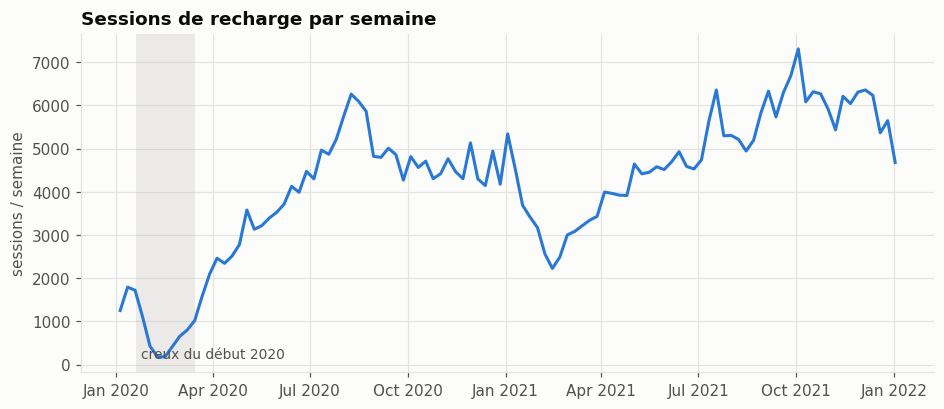

In [4]:
weekly = sessions.set_index("start_time").resample("W").size()

fig, ax = plt.subplots()
ax.plot(weekly.index, weekly.values, color=PALETTE[0])
ax.axvspan(pd.Timestamp("2020-01-20"), pd.Timestamp("2020-03-15"), color=NEUTRAL, alpha=0.25, lw=0)
ax.text(pd.Timestamp("2020-01-25"), 0.04, "creux du début 2020", color=INK_2, fontsize=9,
        transform=ax.get_xaxis_transform())
ax.set_title("Sessions de recharge par semaine")
ax.set_ylabel("sessions / semaine")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

**Constat** :**Constat** : l'activité s'effondre presque à zéro entre fin janvier et février 2020, puis remonte toute l'année jusqu'à environ 6 000 sessions par semaine en août 2020. Un second creux net apparaît vers février 2021, probablement le Nouvel An chinois (12 février 2021). L'activité atteint environ 7 000 sessions par semaine à l'automne 2021 : le volume a presque doublé sur la période.

## 2. Les sites et les bornes se ressemblent-ils ?

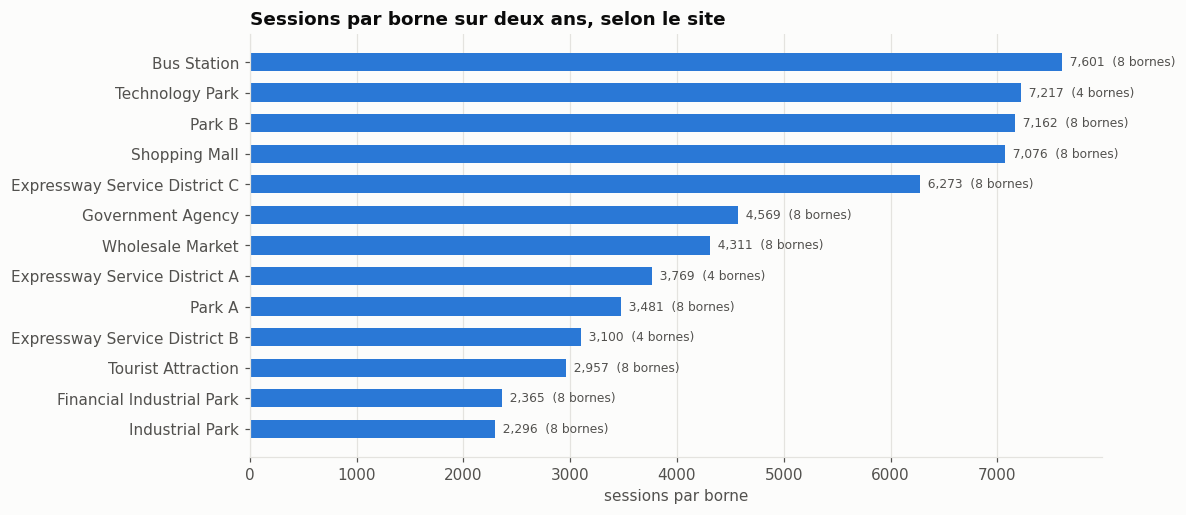

In [5]:
by_site = (sessions.groupby("site")
           .agg(sessions=("post_id", "size"), bornes=("post_id", "nunique"))
           .assign(sessions_par_borne=lambda d: d.sessions / d.bornes)
           .sort_values("sessions_par_borne"))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(by_site.index, by_site["sessions_par_borne"], color=PALETTE[0], height=0.6)
ax.set_title("Sessions par borne sur deux ans, selon le site")
ax.set_xlabel("sessions par borne")
ax.grid(axis="y", visible=False)
for y, (v, b) in enumerate(zip(by_site["sessions_par_borne"], by_site["bornes"])):
    ax.text(v, y, f"  {v:,.0f}  ({b} bornes)", va="center", fontsize=8, color=INK_2)
plt.show()

**Constat** : l'usage varie d'un facteur 3 selon le site : environ 7 600 sessions par borne à la Bus Station, contre environ 2 300 à l'Industrial Park et au Financial Industrial Park.


## 3. Comment les sessions se terminent-elles ?

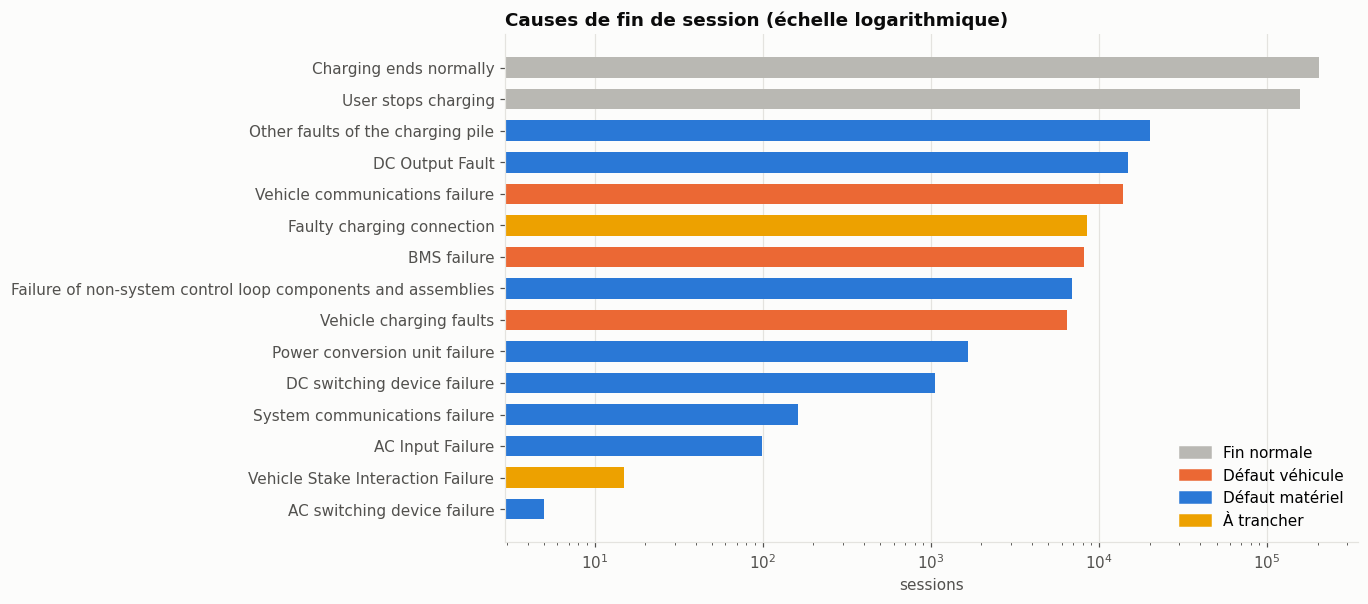

,sessions,part_pct
family,,
Fin normale,359143,81.42
Défaut matériel,44845,10.17
Défaut véhicule,28535,6.47
À trancher,8554,1.94


In [6]:
causes = (sessions.groupby(["end_cause", "family"]).size()
          .rename("sessions").reset_index()
          .sort_values("sessions"))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(causes["end_cause"], causes["sessions"],
        color=causes["family"].map(FAMILY_COLORS), height=0.65)
ax.set_xscale("log")
ax.set_title("Causes de fin de session (échelle logarithmique)")
ax.set_xlabel("sessions")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
ax.legend(handles, FAMILY_COLORS.keys(), loc="lower right")
plt.show()

sessions["family"].value_counts().to_frame("sessions").assign(
    part_pct=lambda d: (d.sessions / d.sessions.sum() * 100).round(2))

**Constat** : 81,4 % des sessions se terminent normalement, 10,2 % par un défaut matériel (44 845 sessions), 6,5 % par un défaut véhicule et 1,9 % par une cause à trancher. Les causes vont de plus de 100 000 sessions à une poignée (AC switching device failure).


## 4. Défauts matériels et défauts véhicule évoluent-ils de la même façon ?


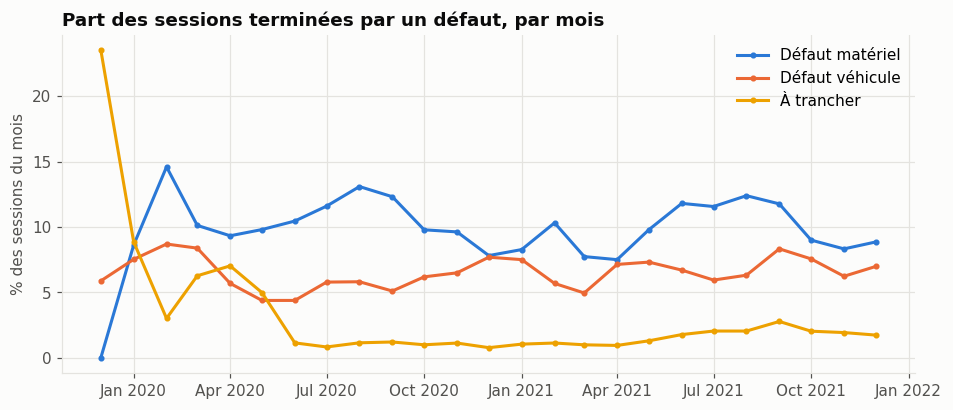

In [7]:
monthly = (sessions.groupby("month")["family"]
           .value_counts(normalize=True).unstack(fill_value=0) * 100)

fig, ax = plt.subplots()
for fam in ["Défaut matériel", "Défaut véhicule", "À trancher"]:
    ax.plot(monthly.index, monthly[fam], color=FAMILY_COLORS[fam], label=fam, marker="o", ms=3)
ax.set_title("Part des sessions terminées par un défaut, par mois")
ax.set_ylabel("% des sessions du mois")
ax.legend(loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()

**Constat** : les défauts matériels oscillent entre 8 et 15 % des sessions selon les mois, et les défauts véhicule suivent une autre courbe : ce sont deux phénomènes distincts. « Faulty charging connection » passe de 23,5 % en décembre 2019 à 4,99 % en mai 2020, puis chute à 1,15 % en juin 2020 et reste autour de 1 % pendant un an. 

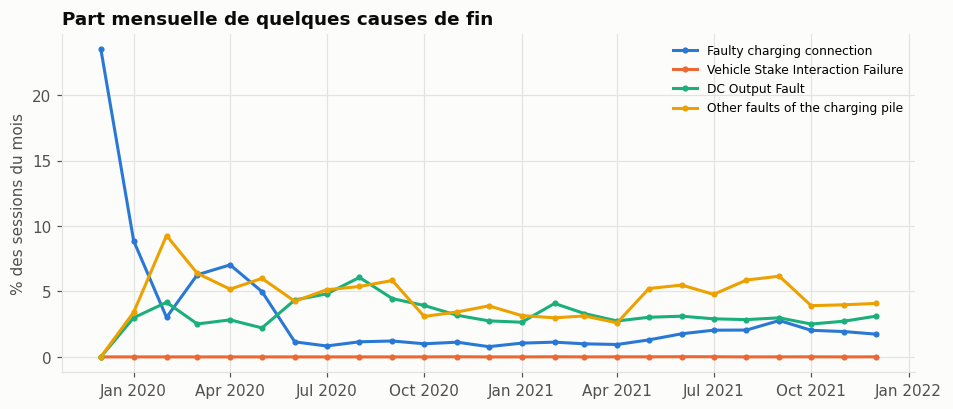

end_cause,DC Output Fault,Faulty charging connection,Other faults of the charging pile,Vehicle Stake Interaction Failure
month,,,,
2019-12-01,0.00,23.53,0.00,0.00
2020-01-01,2.99,8.86,3.41,0.00
2020-02-01,4.17,3.02,9.27,0.00
2020-03-01,2.52,6.27,6.38,0.00
2020-04-01,2.83,7.03,5.17,0.00
2020-05-01,2.22,4.99,6.00,0.00
2020-06-01,4.35,1.15,4.25,0.00
2020-07-01,4.81,0.84,5.13,0.00
2020-08-01,6.07,1.15,5.38,0.00


In [13]:
# Hypothèse : changement de codage des causes "à trancher" en 2020 ?
to_check = cfg["to_test"] + ["DC Output Fault", "Other faults of the charging pile"]
counts = (sessions[sessions["end_cause"].isin(to_check)]
          .groupby(["month", "end_cause"]).size().unstack(fill_value=0))
share = counts.div(sessions.groupby("month").size(), axis=0) * 100

fig, ax = plt.subplots()
for i, cause in enumerate(to_check):
    ax.plot(share.index, share[cause], label=cause, color=PALETTE[i], marker="o", ms=3)
ax.set_title("Part mensuelle de quelques causes de fin")
ax.set_ylabel("% des sessions du mois")
ax.legend(fontsize=8)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.show()
share.round(2)

## 5. Les défauts matériels sont-ils concentrés sur quelques bornes ?


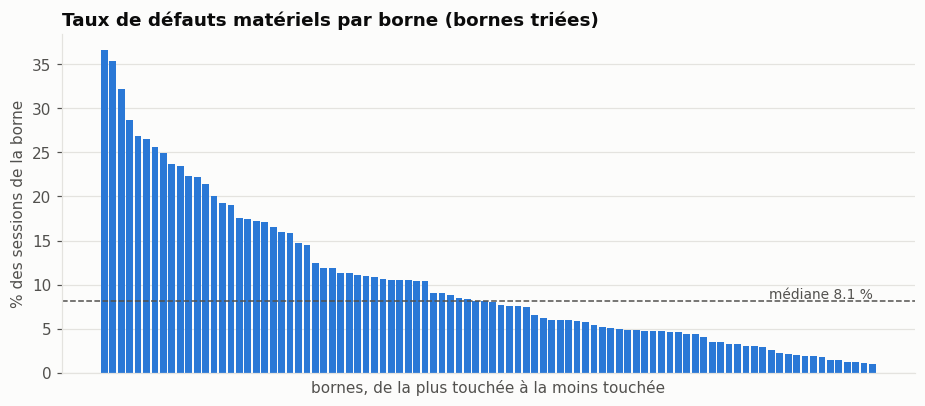

In [8]:
per_post = (sessions.assign(hw=sessions["family"].eq("Défaut matériel"))
            .groupby("post_id").agg(sessions=("hw", "size"), hw=("hw", "sum")))
per_post["taux_pct"] = per_post["hw"] / per_post["sessions"] * 100
per_post = per_post.sort_values("taux_pct", ascending=False)
median = per_post["taux_pct"].median()

fig, ax = plt.subplots()
ax.bar(range(len(per_post)), per_post["taux_pct"], color=PALETTE[0], width=0.8)
ax.axhline(median, color=INK_2, lw=1, ls="--")
ax.text(len(per_post) - 1, median, f"médiane {median:.1f} %", ha="right", va="bottom", fontsize=9, color=INK_2)
ax.set_title("Taux de défauts matériels par borne (bornes triées)")
ax.set_ylabel("% des sessions de la borne")
ax.set_xlabel("bornes, de la plus touchée à la moins touchée")
ax.set_xticks([])
plt.show()

**Constat** : le taux de défauts matériels varie de plus de 35 % des sessions pour la borne la plus touchée à environ 1 % pour la moins touchée, avec une médiane de 8,1 %. Une dizaine de bornes dépassent 20 %.


## 6. Plus une borne sert, plus elle a de défauts ?

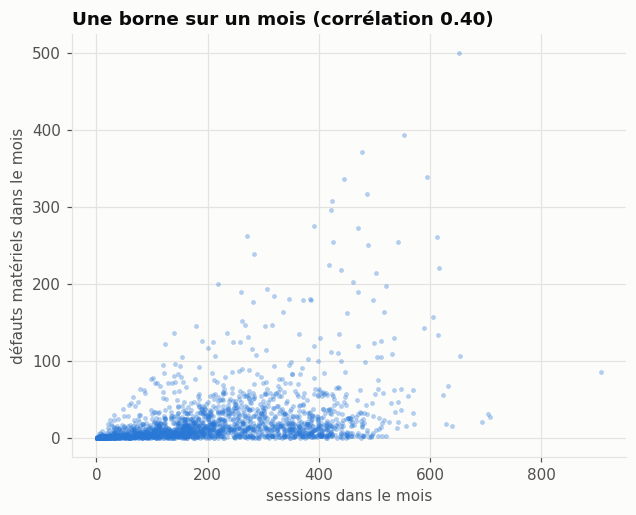

In [9]:
pm = (sessions.assign(hw=sessions["family"].eq("Défaut matériel"))
      .groupby(["post_id", "month"]).agg(sessions=("hw", "size"), hw=("hw", "sum")))

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(pm["sessions"], pm["hw"], s=10, alpha=0.35, color=PALETTE[0], lw=0)
corr = pm["sessions"].corr(pm["hw"])
ax.set_title(f"Une borne sur un mois (corrélation {corr:.2f})")
ax.set_xlabel("sessions dans le mois")
ax.set_ylabel("défauts matériels dans le mois")
plt.show()

**Constat** : la corrélation entre le nombre de sessions et le nombre de défauts matériels d'une borne sur un mois n'est que de 0,40 : l'usage n'explique qu'une partie des défauts. Certains mois sortent nettement du nuage, avec 200 à 500 défauts pour 400 à 650 sessions.


## 7. Toutes les bornes sont-elles actives sur toute la période ?


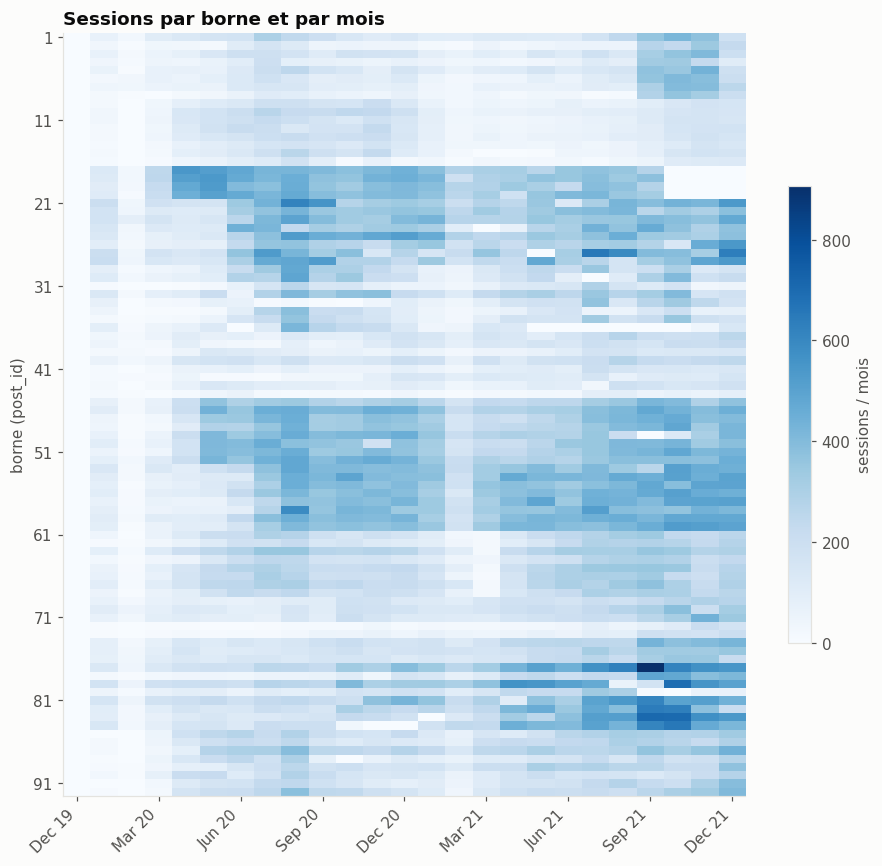

,,dernière session
post_id,site,
19,Technology Park,2021-09-28 19:16:27
17,Technology Park,2021-09-28 20:08:03
18,Technology Park,2021-09-28 20:30:53
20,Technology Park,2021-09-28 20:51:02
80,Expressway Service District C,2021-12-06 15:21:20
1,Tourist Attraction,2021-12-13 10:54:57
3,Tourist Attraction,2021-12-13 10:59:45
5,Tourist Attraction,2021-12-13 11:05:31
6,Tourist Attraction,2021-12-13 12:23:47


In [10]:
activity = sessions.pivot_table(index="post_id", columns="month", values="start_time",
                                aggfunc="size", fill_value=0)

fig, ax = plt.subplots(figsize=(10, 9))
im = ax.imshow(activity.values, aspect="auto", cmap=BLUE_RAMP, interpolation="nearest")
ax.set_title("Sessions par borne et par mois")
ax.set_ylabel("borne (post_id)")
step = 3
ax.set_xticks(range(0, len(activity.columns), step))
ax.set_xticklabels([d.strftime("%b %y") for d in activity.columns[::step]], rotation=45, ha="right")
ax.set_yticks(range(0, len(activity.index), 10))
ax.set_yticklabels(activity.index[::10])
ax.grid(False)
fig.colorbar(im, ax=ax, label="sessions / mois", shrink=0.6)
plt.show()

last = sessions.groupby(["post_id", "site"])["start_time"].max().sort_values().head(10)
last.to_frame("dernière session")

Un mois **blanc** = aucune session. Une bande blanche qui commence et ne s'arrête plus = une borne arrêtée.

**Constat** : la corrélation entre le nombre de sessions et le nombre de défauts matériels d'une borne sur un mois n'est que de 0,40 : l'usage n'explique qu'une partie des défauts. Certains mois sortent nettement du nuage, avec 200 à 500 défauts pour 400 à 650 sessions.


## 8. Durées et énergies : y a-t-il des sessions anormales ?

*Pourquoi c'est important* : des sessions de 0 minute ou de 0 kWh sont soit des erreurs d'enregistrement, soit des **tentatives de recharge ratées**, peut-être un signe de borne défaillante. 

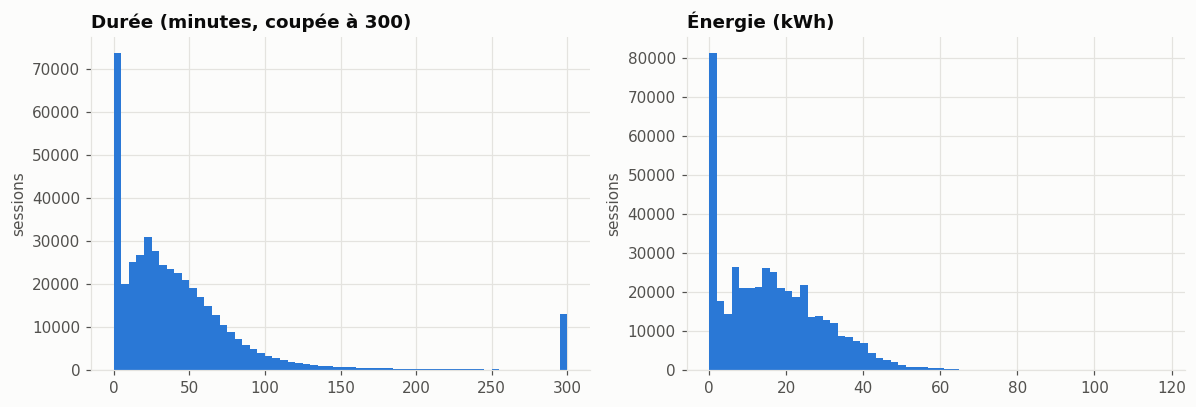

,sessions,part_%
durée = 0 min,5.0,0.00
durée < 1 min,19024.0,4.31
durée >= 23 h,7.0,0.00
énergie = 0 kWh,54621.0,12.38
fin avant le début,0.0,0.00


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(sessions["duration_min"].clip(upper=300), bins=60, color=PALETTE[0])
axes[0].set_title("Durée (minutes, coupée à 300)")
axes[1].hist(sessions["energy_kwh"], bins=60, color=PALETTE[0])
axes[1].set_title("Énergie (kWh)")
for ax in axes:
    ax.set_ylabel("sessions")
plt.tight_layout()
plt.show()

checks = {
    "durée = 0 min": sessions["duration_min"].eq(0),
    "durée < 1 min": sessions["duration_min"].lt(1),
    "durée >= 23 h": sessions["duration_min"].ge(23 * 60),
    "énergie = 0 kWh": sessions["energy_kwh"].eq(0),
    "fin avant le début": sessions["end_time"].lt(sessions["start_time"]),
}
table = pd.DataFrame({k: {"sessions": int(v.sum()), "part_%": round(v.mean() * 100, 2)} for k, v in checks.items()}).T
table

In [12]:
# Les sessions vides sont-elles plus souvent des défauts ?
empty = sessions["energy_kwh"].eq(0)
(pd.crosstab(empty.rename("énergie = 0"), sessions["family"], normalize="index") * 100).round(1)

family,Défaut matériel,Défaut véhicule,Fin normale,À trancher
énergie = 0,,,,
False,5.5,2.4,90.6,1.5
True,42.9,35.6,16.6,4.9


**Constat** : très peu d'incohérences : 5 sessions de 0 minute, 7 sessions de 23 heures ou plus, aucune fin avant le début. En revanche, 54 621 sessions (12,4 %) délivrent 0 kWh et 19 024 (4,3 %) durent moins d'une minute. Parmi les sessions à 0 kWh, 42,9 % sont des défauts matériels et 35,6 % des défauts véhicule, contre 5,5 % et 2,4 % pour les autres sessions.
